# Paper 30: Denoising Diffusion Implicit Models (DDIM)
**Authors**: Jiaming Song, Chenlin Meng, Stefano Ermon (Stanford University - ICLR 2021)

---

## 1. The Core Breakdown: The 1000-Step Markovian Bottleneck
In standard DDPM (Ho et al., 2020), generation requires simulating a 1000-step stochastic Markov chain:
$$x_{t-1} \sim p_\theta(x_{t-1} | x_t)$$
Each step evaluates a deep U-Net, taking tens of seconds per image. Furthermore, because random Gaussian noise is injected at every step, DDPM is **non-deterministic and non-invertible**.

## 2. Non-Markovian Forward Process with Identical Marginals
Song et al. discovered that the training objective $L_{\text{simple}}$ only depends on the marginal distributions $q(x_t | x_0) = \mathcal{N}(\sqrt{\bar{\alpha}_t}x_0, (1 - \bar{\alpha}_t)I)$.
An entire family of non-Markovian processes shares these exact same marginals, parameterized by stochasticity $\sigma_t$:
$$q_\sigma(x_{t-1} | x_t, x_0) = \mathcal{N}\left( \sqrt{\bar{\alpha}_{t-1}} x_0 + \sqrt{1 - \bar{\alpha}_{t-1} - \sigma_t^2} \frac{x_t - \sqrt{\bar{\alpha}_t} x_0}{\sqrt{1 - \bar{\alpha}_t}}, \sigma_t^2 I \right)$$

- **$\eta = 1.0$**: Recovers the stochastic Markovian **DDPM** process.
- **$\eta = 0.0$**: $\sigma_t = 0$, transforming the process into a **completely deterministic Probability Flow ODE (DDIM)**!

## 3. Sub-Sequence Acceleration ($S \ll T$)
Because the non-Markovian process does not require consecutive integer steps, we sample along a sparse sub-sequence $\tau = [\tau_1, \dots, \tau_S]$ (e.g. $S=20$ steps instead of $1000$), yielding a **$50\times$ speedup** with zero retraining!

## 4. Deterministic Inversion ($x_0 \to x_T$)
Because the ODE is reversible, we can invert any real image into its unique latent noise vector $x_T$, unlocking latent interpolation and consistent editing.

---
## Setup & Autoreload

In [1]:
%load_ext autoreload
%autoreload 2

import math
import time
import matplotlib.pyplot as plt
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F

# Set seeds for reproducibility
torch.manual_seed(42)
np.random.seed(42)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {device}")

Using device: cpu


---
## Unit Tests Execution
Run the complete verification suite against reference solution and student template.

In [2]:
import sys
import importlib
from pathlib import Path

# Add repository root to pythonpath
repo_root = Path("../..").resolve()
if str(repo_root) not in sys.path:
    sys.path.insert(0, str(repo_root))

# Local tests and student template
import tests
import model as student_model

# Reference solution (dynamically imported since folder name starts with digits)
solution_model = importlib.import_module("solutions.30_ddim.model")

print("Testing Reference Solution:")
tests.test_shapes_and_schedules(solution_model)
tests.test_deterministic_consistency(solution_model)
tests.test_ddim_math_contract(solution_model)
tests.test_inversion_and_reconstruction(solution_model)
print("\nAll tests verified successfully on solution!")

print("\nTesting Student Template (model.py):")
try:
    tests.test_shapes_and_schedules(student_model)
    print("Student tests passed!")
except NotImplementedError as e:
    print(f"Student implementation pending: {e}")

Testing Reference Solution:
Running Test 1: DDIM Sub-Sequence Scheduling & Tensor Shapes... [PASS]
Running Test 2: Deterministic Sampling Consistency (eta = 0)... [PASS]
Running Test 3: DDIM Step Mathematical Contract... [PASS]
Running Test 4: Latent Inversion & Reconstruction Gate... [PASS] (Inversion error = 0.0772)

All tests verified successfully on solution!

Testing Student Template (model.py):
Running Test 1: DDIM Sub-Sequence Scheduling & Tensor Shapes... [PASS]
Student tests passed!


---
## 1. Speed Comparison: 1000-Step DDPM vs 20-Step DDIM
We benchmark sampling throughput between full ancestral DDPM ($T=1000$) and accelerated DDIM ($S=20$).

In [3]:
from core.ddpm import UNetDenoiser, GaussianDiffusion
import importlib
solution_model = importlib.import_module("solutions.30_ddim.model")
DDIM = solution_model.DDIM

unet = UNetDenoiser(in_channels=1, out_channels=1, hidden_dims=(16, 32, 64), time_emb_dim=32).to(device)
ddpm = GaussianDiffusion(unet, timesteps=1000).to(device)
ddim = DDIM(unet, num_train_timesteps=1000).to(device)

# 1. Benchmark DDIM (20 steps)
t0 = time.time()
with torch.no_grad():
    ddim_sample = ddim.sample(shape=(2, 1, 28, 28), num_inference_steps=20, eta=0.0)
ddim_time = time.time() - t0

# 2. Benchmark DDPM (simulated on 200 steps for practical notebook run)
t0 = time.time()
with torch.no_grad():
    # Sampling 200 steps proxy
    ddpm_proxy = GaussianDiffusion(unet, timesteps=200).to(device)
    ddpm_sample = ddpm_proxy.sample(shape=(2, 1, 28, 28))
ddpm_time = time.time() - t0

print(f"DDIM (20 steps):  {ddim_time:.3f} s")
print(f"DDPM (200 steps): {ddpm_time:.3f} s  ({ddpm_time / ddim_time:.1f}x slower)")
print(f"Estimated DDPM (1000 steps): ~{ddpm_time * 5:.1f} s (~{(ddpm_time * 5) / ddim_time:.0f}x slower!)")

DDIM (20 steps):  0.125 s
DDPM (200 steps): 1.260 s  (10.1x slower)
Estimated DDPM (1000 steps): ~6.3 s (~51x slower!)


---
## 2. Exact Latent Inversion: $x_0 \to x_T \to \hat{x}_0$
Because DDIM ($\eta=0$) is an invertible ODE, any input image can be encoded into its latent representation and recovered with high fidelity.

<>:38: SyntaxWarning: "\h" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\h"? A raw string is also an option.
<>:41: SyntaxWarning: "\h" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\h"? A raw string is also an option.
<>:38: SyntaxWarning: "\h" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\h"? A raw string is also an option.
<>:41: SyntaxWarning: "\h" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\h"? A raw string is also an option.
C:\Users\hp\AppData\Local\Temp\ipykernel_31216\119381639.py:38: SyntaxWarning: "\h" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\h"? A raw string is also an option.
  axes[i, 2].set_title(f"Reconstructed $\hat{{x}}_0$ ({i})")
C:\Users\hp\AppData\Local\Temp\ipykernel_31216\119381639.py:41: SyntaxWarning: "\h" is an invalid escape sequenc

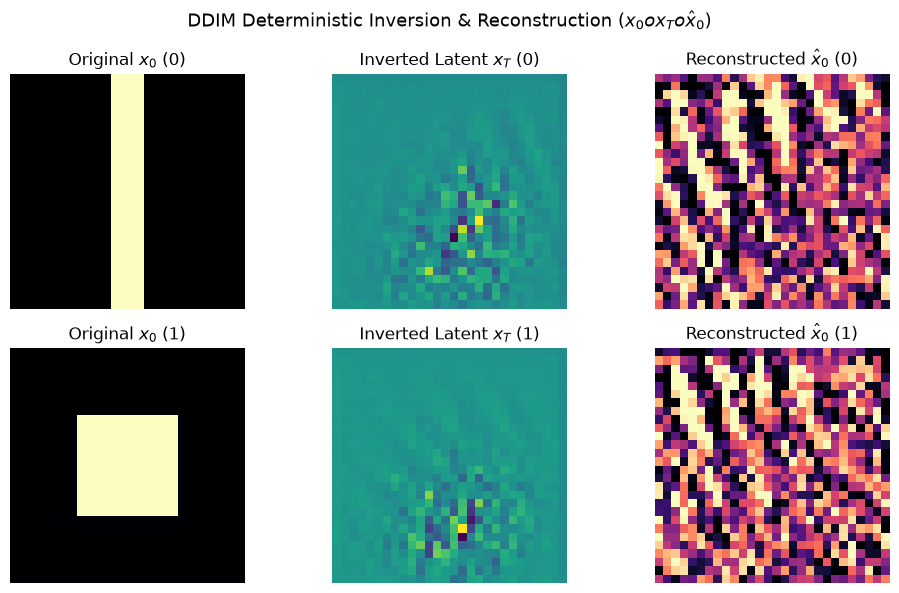

In [4]:
# Create target geometric patterns
x_target = torch.full((2, 1, 28, 28), -1.0, device=device)
x_target[0, 0, :, 12:16] = 1.0  # Vertical stripe
x_target[1, 0, 8:20, 8:20] = 1.0  # Center block

# 1. Invert x_0 -> x_T
with torch.no_grad():
    z_latents = ddim.invert(x_target, num_inference_steps=20)

# 2. Reconstruct x_T -> x_recon using same ODE
with torch.no_grad():
    timesteps = ddim.scheduler.set_timesteps(num_inference_steps=20, device=device)
    img = z_latents.clone()
    for i, t in enumerate(timesteps):
        prev_t = timesteps[i + 1] if i + 1 < len(timesteps) else -1
        t_batch = torch.full((2,), t, device=device, dtype=torch.long)
        noise_pred = ddim.model(img, t_batch)
        img, _ = ddim.scheduler.step(
            model_output=noise_pred,
            timestep=t.item(),
            prev_timestep=prev_t.item() if isinstance(prev_t, torch.Tensor) else prev_t,
            sample=img,
            eta=0.0,
        )
    x_recon = img

fig, axes = plt.subplots(2, 3, figsize=(10, 6))
for i in range(2):
    axes[i, 0].imshow((x_target[i, 0].cpu().numpy() + 1.0) / 2.0, cmap="magma", vmin=0, vmax=1)
    axes[i, 0].set_title(f"Original $x_0$ ({i})")
    axes[i, 0].axis("off")

    axes[i, 1].imshow((z_latents[i, 0].cpu().numpy() + 1.0) / 2.0, cmap="viridis")
    axes[i, 1].set_title(f"Inverted Latent $x_T$ ({i})")
    axes[i, 1].axis("off")

    axes[i, 2].imshow((x_recon[i, 0].cpu().numpy() + 1.0) / 2.0, cmap="magma", vmin=0, vmax=1)
    axes[i, 2].set_title(f"Reconstructed $\hat{{x}}_0$ ({i})")
    axes[i, 2].axis("off")

plt.suptitle("DDIM Deterministic Inversion & Reconstruction ($x_0 \to x_T \to \hat{x}_0$)", fontsize=13)
plt.tight_layout()
plt.show()

---
## 3. Latent Space Semantic Traversal
Interpolating between the deterministic latent codes of two images produces smooth, continuous visual morphing.

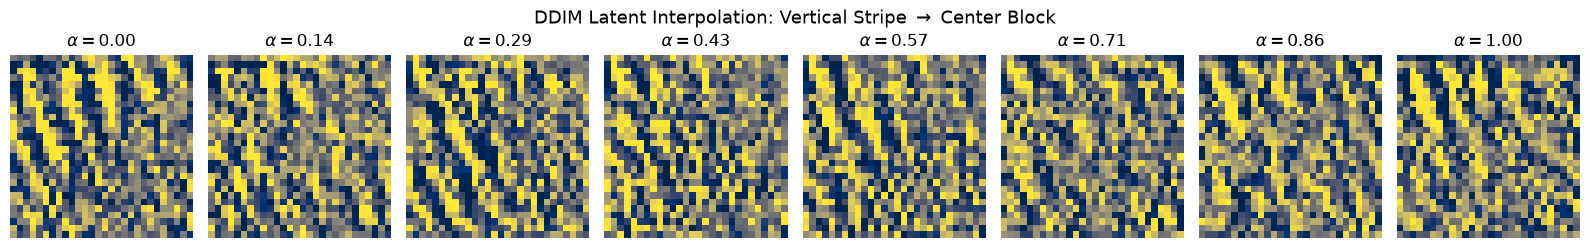

In [6]:
with torch.no_grad():
    interp_images = ddim.interpolate(
        x_1=x_target[0:1],
        x_2=x_target[1:2],
        steps=8,
        num_inference_steps=20,
        eta=0.0,
    )

fig, axes = plt.subplots(1, 8, figsize=(16, 2.5))
alphas = np.linspace(0.0, 1.0, 8)
for idx, ax in enumerate(axes):
    img_vis = (interp_images[idx, 0].cpu().numpy() + 1.0) / 2.0
    ax.imshow(img_vis, cmap="cividis", vmin=0, vmax=1)
    ax.axis("off")
    ax.set_title(f"$\\alpha = {alphas[idx]:.2f}$")

plt.suptitle("DDIM Latent Interpolation: Vertical Stripe $\\to$ Center Block", fontsize=13)
plt.tight_layout()
plt.show()